# 5 · Find the right PDF page and video moment

A PDF is a container, not a guarantee of searchable text. A video is a sequence,
not one giant image. In this final notebook we give both formats smaller evidence
units with stable page numbers or timestamps, then reuse the same retrieval ideas.

Allow **45–65 minutes**. We will extract and render a two-page PDF, decode a real
12-second video, align six sampled frames to transcript windows, fuse searches at
the segment level, and assemble a grounded reader request.

Our video is **silent**. Its companion transcript is hand-authored teaching material,
not speech recognition output. A production pipeline would create or receive a
timestamped transcript separately and measure its errors.

In [1]:
import os, sys, json, copy
from pathlib import Path
import numpy as np
from IPython.display import display, Image, Markdown
from dotenv import load_dotenv, find_dotenv

# Works when Jupyter starts either here or at the repository root.
candidates = [Path.cwd(), Path.cwd() / "evals" / "multimodal"]
MODULE = next((p for p in candidates if (p / "lab.py").exists()), None)
if MODULE is None:
    raise RuntimeError("Start Jupyter from evals/multimodal or the repository root.")
os.chdir(MODULE)
if str(MODULE) not in sys.path:
    sys.path.insert(0, str(MODULE))
load_dotenv(find_dotenv())  # Secrets live outside the notebook.
from lab import (
    CORPUS, GOLD, Record, LexicalEncoder, ColorEncoder, QdrantIndex,
    load_corpus, load_reference_parses, normalize, validate_parse,
    flatten_parse, build_strategy_a, toy_shared_space, show_hits, rrf,
    evaluate, check_data_points, feature_fingerprint, read_pdf,
    sample_keyframes, build_video_records, timestamp, evidence_bundle,
)
RUN_MODELS = os.getenv("MM_RUN_MODELS") == "1"
RUN_LIVE = os.getenv("MM_RUN_LIVE") == "1"
print("Local pretrained models enabled:", RUN_MODELS)
print("Remote API calls enabled:", RUN_LIVE)
print("Default path: explicit lexical/color baselines, real in-memory Qdrant.")

Local pretrained models enabled: False
Remote API calls enabled: False
Default path: explicit lexical/color baselines, real in-memory Qdrant.


/Users/pmui/dev/agents2026/evals/multimodal/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


![PDF pages may have native text, raster pixels, or both; preserve page provenance.](assets/09_pdf.svg)

## Step 1 · Test whether a PDF contains extractable text

Page 1 of our report contains native text. Page 2 contains only a raster chart image.
`pypdfium2` extracts available text and renders both pages to PNG. Rendering is not OCR:
it turns the page into pixels, but does not read words from those pixels.

Predict which page has almost no extracted characters. Keep a rendered image even
for text-rich pages: extraction can lose columns, reading order, equations, or the
relationship between a chart and its legend.

[{'id': 'solar_lab_report-03ee2379617793bc#page=1',
  'page': 1,
  'text_characters': 256,
  'parent': 'solar_lab_report-03ee2379617793bc'},
 {'id': 'solar_lab_report-03ee2379617793bc#page=2',
  'page': 2,
  'text_characters': 0,
  'parent': 'solar_lab_report-03ee2379617793bc'}]

Page 1 extracted text:
 Cedar School solar lab report
Page 1: native PDF text
The school reviews solar energy each Thursday.
Students compare monthly energy in the chart on page 2.
A chart can show a pattern without proving its cause.
Report version: classroom demonstration.


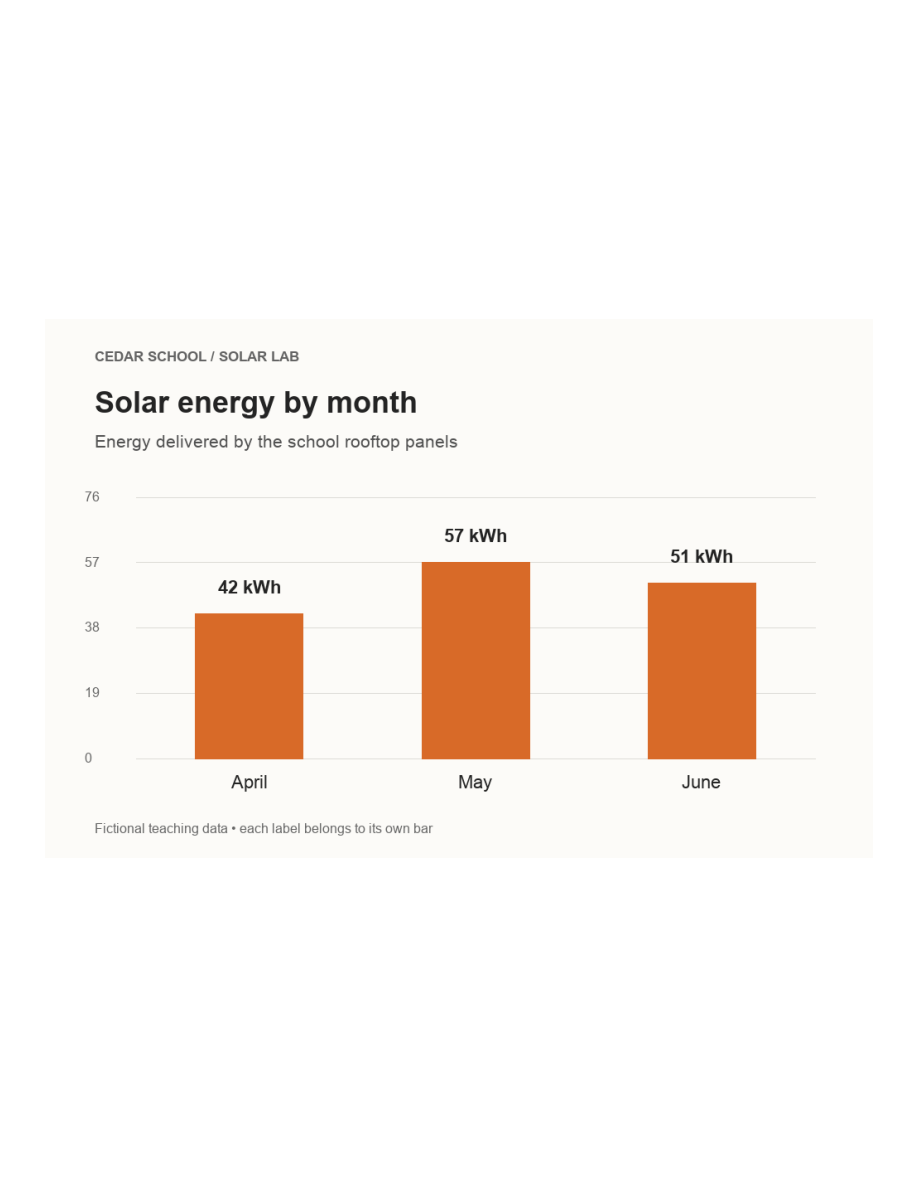

In [2]:
pages = read_pdf(CORPUS / "solar_lab_report.pdf")
display([{"id": p.id, "page": p.meta["page"], "text_characters": len(p.text), "parent": p.parent_id} for p in pages])
print("Page 1 extracted text:\n", pages[0].text)
display(Image(filename=pages[1].path, width=450))

The raster chart page has no native text layer, although you can read it visually.
A text-only PDF extractor did not fail to download the report; it reached a boundary
of what the file stores as text. Options include OCR, vision parsing, or a visual
page-retrieval model. More advanced document retrieval can represent many patches
per page, but this tutorial focuses on one representation per evidence unit.

## Step 2 · Index PDF evidence with page citations

For an offline Strategy A demonstration, page 1 uses extracted text and page 2 uses
the **already labelled hand-authored energy-chart fixture**. This is not automatic
OCR of the PDF. The fixture is explicitly attached because our corpus builder put
that known chart on page 2. A new unknown PDF would need a real extraction path.

Every page retains a parent snapshot ID, its page number, and a rendered image path.
The snapshot ID includes the filename stem and a short source hash. Two different
files named `report.pdf` can coexist; a corrected file gets a new version identity.
A larger catalog would separately track a logical document ID across versions.
A citation to an entire 200-page document is less helpful than a citation to the page
that contains the evidence.

Rendered pages live in a folder named from the PDF's name and content hash, so
rendering another report—or a corrected version—does not overwrite old evidence.

In [3]:
from dataclasses import replace
page_two_caption = flatten_parse(load_reference_parses()["chart_energy"])
pdf_records = [replace(pages[0], text=pages[0].text),
               replace(pages[1], text=page_two_caption,
                       meta={**pages[1].meta, "parse_source": "hand-authored known-chart fixture"})]
pdf_encoder = LexicalEncoder([p.text for p in pdf_records])
pdf_index = QdrantIndex(pdf_records, pdf_encoder.embed([p.text for p in pdf_records]), "pdf_pages")
pdf_hits = pdf_index.search(pdf_encoder.embed(["May energy kWh"])[0], k=1)
display(show_hits(pdf_hits))
print("Cite:", pdf_hits[0]["source_id"], "from", pdf_hits[0]["parent_id"])

[{'rank': 1,
  'id': 'solar_lab_report-03ee2379617793bc#page=2',
  'source': 'solar_lab_report-03ee2379617793bc#page=2',
  'modality': 'pdf_page',
  'score': 0.5941}]

Cite: solar_lab_report-03ee2379617793bc#page=2 from solar_lab_report-03ee2379617793bc


An image query path could index the rendered page directly instead. Different pages
can need different representations, but record their provenance. Do not call a
manually supplied caption “extracted PDF text.” When reading an answer, attach the
rendered retrieved page so the model can inspect the chart itself.

In [4]:
pdf_bundle = evidence_bundle(pdf_hits, max_images=1)
print("Retrieved-page image attached:", pdf_bundle[0]["images"])
if RUN_LIVE:
    from live import answer_from_bundle
    print(answer_from_bundle("Which month produced the most energy, and how much? Cite the page.", pdf_bundle))
else:
    print("PDF reader skipped. The retrieved page above is available for human inspection.")

Retrieved-page image attached: [{'path': '/Users/pmui/dev/agents2026/evals/multimodal/assets/corpus/pdf_pages/solar_lab_report-03ee2379617793bc/page_02.png'}]
PDF reader skipped. The retrieved page above is available for human inspection.


![Timestamped transcript windows align with sampled visual frames without implying exact event onset.](assets/10_video.svg)

## Step 3 · Treat video as two aligned streams

One stream is what was said: transcript text with start/end times. The other is what
appeared: sampled frames with observation times. They can agree, complement each
other, or conflict. A speaker might discuss the next slide while the previous slide
is still visible.

Our three transcript windows are `[0,4)`, `[4,8)`, and `[8,12)` seconds. The square
bracket includes the start; the parenthesis excludes the end. Therefore a frame at
exactly 4 seconds belongs to the second window, not both.

In [5]:
companion = json.loads((CORPUS / "transcript.json").read_text())
segments = companion["segments"]
print("Transcript provenance:", companion["provenance"])
display(segments)

Transcript provenance: hand-authored companion transcript; video is silent; not ASR output


[{'id': 'seg_000',
  'start': 0.0,
  'end': 4.0,
  'text': 'Here is the monthly rooftop solar energy chart. Compare the spring and summer bars.'},
 {'id': 'seg_001',
  'start': 4.0,
  'end': 8.0,
  'text': 'The controller warning appeared during the inspection. The teacher cleared the blocked vent before restarting.'},
 {'id': 'seg_002',
  'start': 8.0,
  'end': 12.0,
  'text': 'We finish by comparing panel temperatures at the roof, garden, and shade locations.'}]

## Step 4 · Decode and sample actual frames

OpenCV reads the AVI file. We retain one frame every two seconds and compute the
frame's timestamp from its decoded index and the video's frame rate. This works for
our constant-frame-rate teaching video. Variable-frame-rate media needs timestamps
from the media stream rather than assuming `frame_index / fps` is universally exact.

Six frames are enough to inspect three static scenes. Sampling every two seconds
could miss a warning visible for only half a second. Scene-change detection or denser
sampling may help, but each adds cost and still requires evaluation.

[{'id': 'frame_00000', 'seconds': 0.0},
 {'id': 'frame_00010', 'seconds': 2.0},
 {'id': 'frame_00020', 'seconds': 4.0},
 {'id': 'frame_00030', 'seconds': 6.0},
 {'id': 'frame_00040', 'seconds': 8.0},
 {'id': 'frame_00050', 'seconds': 10.0}]

Observed at 00:00.0


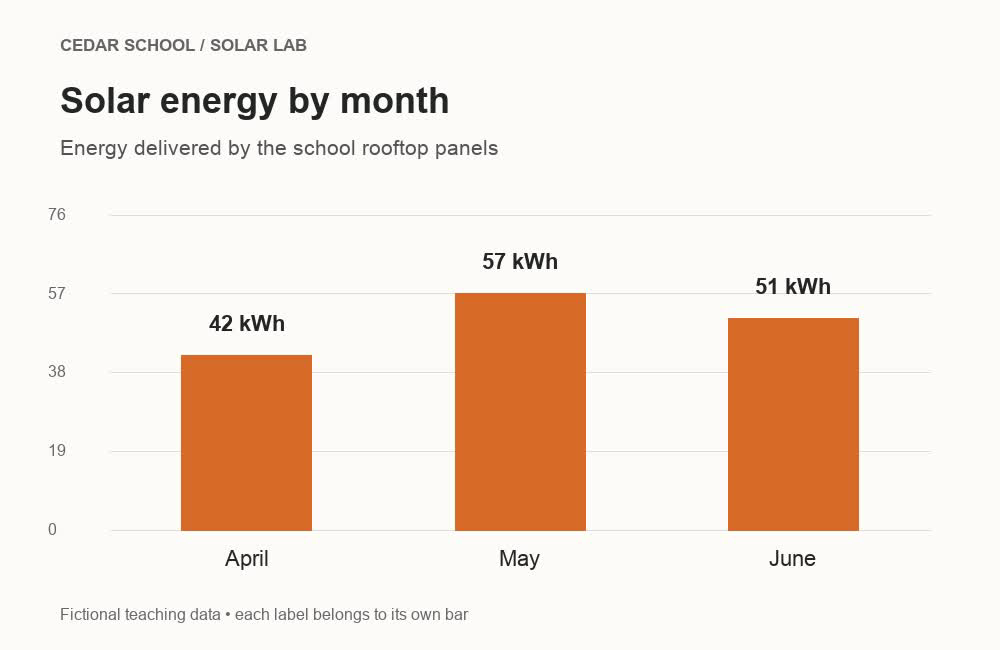

Observed at 00:04.0


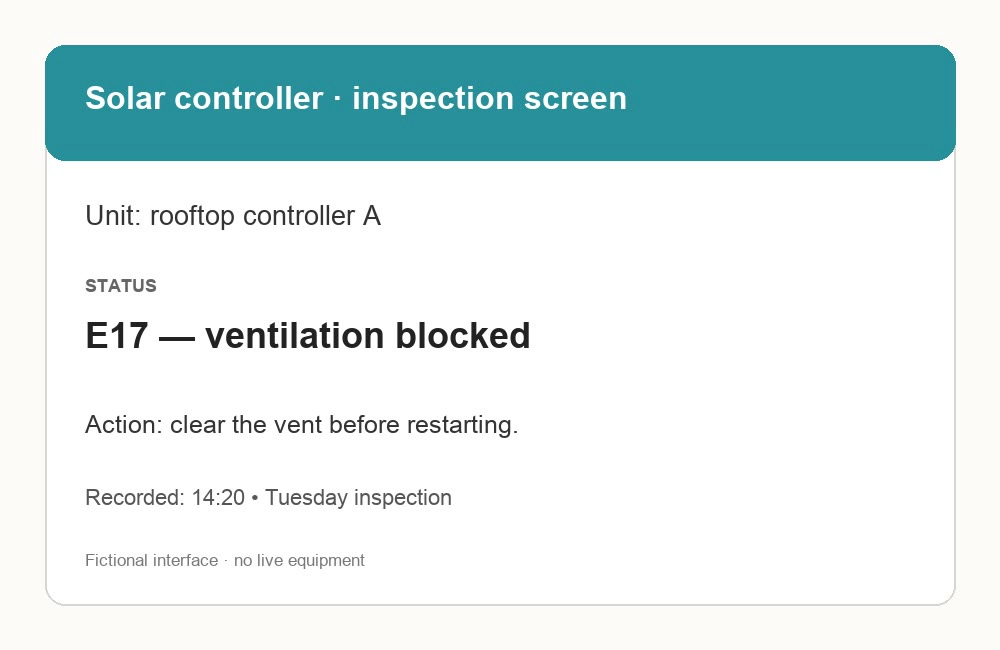

Observed at 00:08.0


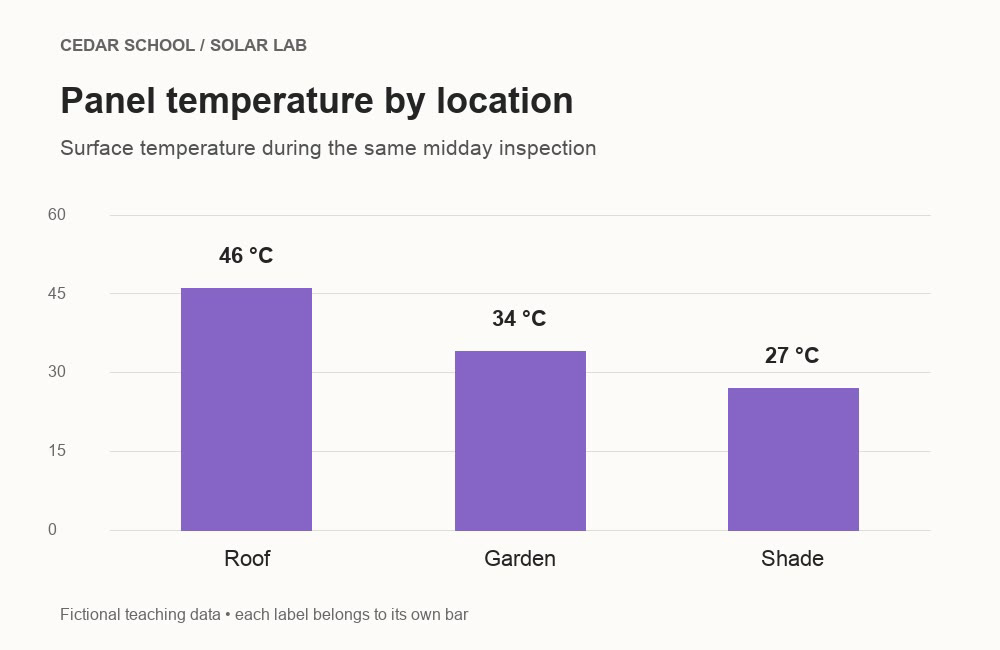

In [6]:
frames = sample_keyframes(CORPUS / "solar_lab_review.avi", every_seconds=2)
display([{ "id": f["id"], "seconds": f["time"] } for f in frames])
for frame in frames[::2]:
    print("Observed at", timestamp(frame["time"]))
    display(Image(filename=frame["path"], width=440))

### Open sampling: frame index → time → selection

The full helper saves PNG files and validates failures. Its core loop is below, run
directly against the actual video. `capture.read()` decodes the next frame; dividing
its index by FPS gives time for this constant-rate fixture. We retain a sample when
its time reaches the next two-second target. `finally` releases the decoder even
if an error occurs.

In [7]:
import cv2
capture = cv2.VideoCapture(str(CORPUS / "solar_lab_review.avi"))
sampled_times = []
try:
    fps = capture.get(cv2.CAP_PROP_FPS)
    if not capture.isOpened() or fps <= 0:
        raise ValueError("The teaching video could not establish a valid frame rate.")
    frame_number, next_target = 0, 0.0
    while True:
        ok, decoded_pixels = capture.read()
        if not ok:
            break
        seconds = frame_number / fps
        if seconds + 1e-8 >= next_target:
            sampled_times.append(seconds)
            next_target += 2.0
        frame_number += 1
finally:
    capture.release()
print("Manually sampled times:", sampled_times)
assert sampled_times == [f["time"] for f in frames]
# Alignment is just the half-open interval rule, applied to observations.
print({s["id"]: [t for t in sampled_times if s["start"] <= t < s["end"]]
       for s in segments})

Manually sampled times: [0.0, 2.0, 4.0, 6.0, 8.0, 10.0]
{'seg_000': [0.0, 2.0], 'seg_001': [4.0, 6.0], 'seg_002': [8.0, 10.0]}


If decoding fails, the helper raises an error. It does not silently substitute
unrelated stills and claim that video sampling worked. If a transcript window has
no observed frame, we keep that gap explicit. A “nearest” frame from a different
window can be convenient context, but must not be presented as an observation
inside the requested interval.

In [8]:
transcript_records, frame_records = build_video_records(segments, frames)
display([{"chunk_id": r.id, "segment_source": r.source_id,
          "whole_video_parent": r.parent_id, "sample_time": r.meta["sample_time"]}
         for r in frame_records])
print("Unique frame IDs:", len({r.id for r in frame_records}) == len(frame_records))
no_frame_text, no_frame_visual = build_video_records(segments, [])
print("Empty-frame case:", len(no_frame_text), "text windows;", len(no_frame_visual), "visual records")

[{'chunk_id': 'frame_00000',
  'segment_source': 'solar_lab_review#seg_000',
  'whole_video_parent': 'solar_lab_review',
  'sample_time': 0.0},
 {'chunk_id': 'frame_00010',
  'segment_source': 'solar_lab_review#seg_000',
  'whole_video_parent': 'solar_lab_review',
  'sample_time': 2.0},
 {'chunk_id': 'frame_00020',
  'segment_source': 'solar_lab_review#seg_001',
  'whole_video_parent': 'solar_lab_review',
  'sample_time': 4.0},
 {'chunk_id': 'frame_00030',
  'segment_source': 'solar_lab_review#seg_001',
  'whole_video_parent': 'solar_lab_review',
  'sample_time': 6.0},
 {'chunk_id': 'frame_00040',
  'segment_source': 'solar_lab_review#seg_002',
  'whole_video_parent': 'solar_lab_review',
  'sample_time': 8.0},
 {'chunk_id': 'frame_00050',
  'segment_source': 'solar_lab_review#seg_002',
  'whole_video_parent': 'solar_lab_review',
  'sample_time': 10.0}]

Unique frame IDs: True
Empty-frame case: 3 text windows; 0 visual records


## Step 5 · Index streams separately, fuse at the segment level

Transcript chunks use word-count vectors. Frame chunks use measured color vectors.
Each frame has a unique ID for storage, but frames in one transcript window share
a **segment source ID**. The complete video is their parent. RRF gives at most one
vote per segment in each list, so two nearly identical frames do not double its vote.

The query below includes both “teal” (a visual clue) and “controller warning” (words
from the transcript). This deliberately fits our teaching baselines. A general natural
language image query would need the optional CLIP encoder from notebook 3.

In [9]:
transcript_encoder = LexicalEncoder([r.text for r in transcript_records])
transcript_index = QdrantIndex(transcript_records,
                              transcript_encoder.embed([r.text for r in transcript_records]), "video_text")
frame_encoder = ColorEncoder()
frame_index = QdrantIndex(frame_records, frame_encoder.embed_images([r.path for r in frame_records]), "video_frames")

def retrieve_video(query, k=2):
    text_hits = transcript_index.search(transcript_encoder.embed([query])[0], k)
    # Request all six frames before source-level dedupe for this tiny corpus.
    visual_hits = frame_index.search(frame_encoder.embed_text([query])[0], len(frame_records))
    return rrf([text_hits, visual_hits])[:k]

video_question = "When does the teal controller warning screen appear?"
video_hits = retrieve_video(video_question, k=2)
display(show_hits(video_hits))
for hit in video_hits:
    print(hit["source_id"], hit["votes"], "distinct evidence chunks:", len(hit["evidence"]))

[{'rank': 1,
  'id': 'seg_001',
  'source': 'solar_lab_review#seg_001',
  'modality': 'video_text',
  'score': 0.0328},
 {'rank': 2,
  'id': 'seg_000',
  'source': 'solar_lab_review#seg_000',
  'modality': 'video_text',
  'score': 0.0323}]

solar_lab_review#seg_001 [{'list': 0, 'rank': 1, 'contribution': 0.01639344262295082}, {'list': 1, 'rank': 1, 'contribution': 0.01639344262295082}] distinct evidence chunks: 3
solar_lab_review#seg_000 [{'list': 0, 'rank': 2, 'contribution': 0.016129032258064516}, {'list': 1, 'rank': 2, 'contribution': 0.016129032258064516}] distinct evidence chunks: 3


The selected controller segment should be supported by both streams. The additional
candidate is not automatically useful. For a production system, choose a candidate
budget, deduplicate near-identical frames, and evaluate whether visual search improves
over the transcript-only baseline on genuinely visual questions.

Here transcript-only retrieval can find a warning discussion, but it cannot read the
exact code because the companion transcript omits it. Visual evidence is needed for
**“Which error code is on screen?”** A color feature can help find the screen; it
cannot read that code itself.

## Step 6 · Attach only evidence from selected segments

Our reader bundle joins transcript text and one sampled frame for each **retrieved**
segment. It prefers the actual frame returned by visual retrieval. When only text
retrieves a segment, it may attach the earliest available frame from that window,
labelled `representative_for_retrieved_transcript`. That label matters: a representative
frame is context, not a frame chosen for matching the visual question.
The bundle does not scan every frame to find the desired answer after retrieval.
The bundle carries the segment interval and each frame's actual sample time.

Inspect those fields before calling a model. A sample observed at 4 seconds supports
“visible in the frame at 00:04.0.” In general, it does not prove the warning first
appeared at exactly 4 seconds. Exact onset needs finer temporal evidence.

In [10]:
video_bundle = evidence_bundle(video_hits, transcript_records, frame_records, max_images=2)
display([{ "source_id": e["source_id"], "window": (e["meta"]["start"], e["meta"]["end"]),
           "sample_times": [i["sample_time"] for i in e["images"]],
           "frame_selection": [i["selection"] for i in e["images"]], "transcript": e["text"]}
          for e in video_bundle])
selected = {hit["source_id"] for hit in video_hits}
assert all(item["source_id"] in selected for item in video_bundle)
if RUN_LIVE:
    from live import answer_from_bundle
    print(answer_from_bundle("What error code is visible during the controller warning discussion? Cite the observed frame time and explain what the transcript says happened.", video_bundle))
else:
    print("Video reader skipped. No generated answer or model-read timestamp is claimed.")

[{'source_id': 'solar_lab_review#seg_001',
  'window': (4.0, 8.0),
  'sample_times': [4.0],
  'frame_selection': ['retrieved_frame'],
  'transcript': 'The controller warning appeared during the inspection. The teacher cleared the blocked vent before restarting.'},
 {'source_id': 'solar_lab_review#seg_000',
  'window': (0.0, 4.0),
  'sample_times': [0.0],
  'frame_selection': ['retrieved_frame'],
  'transcript': 'Here is the monthly rooftop solar energy chart. Compare the spring and summer bars.'}]

Video reader skipped. No generated answer or model-read timestamp is claimed.


## Step 7 · Check time alignment, not only retrieved IDs

A system can retrieve the correct video but the wrong moment. Our tiny check asks
whether the top retrieved segment overlaps the labelled discussion window `[4,8)`.
**Intersection over union (IoU)** divides the overlapping duration by the combined
duration. Exact matching windows score 1; disjoint windows score 0.

This evaluates segment localization, not whether the model correctly read `E17`.
Answer correctness, code transcription, and citation support need their own checks.

In [11]:
def temporal_iou(predicted, expected):
    intersection = max(0., min(predicted[1], expected[1]) - max(predicted[0], expected[0]))
    union = max(predicted[1], expected[1]) - min(predicted[0], expected[0])
    return intersection / union if union > 0 else 0.

top = video_hits[0]
predicted_window = (top["meta"]["start"], top["meta"]["end"])
expected_window = (4., 8.)  # Evaluation label, never sent to the reader prompt.
print("Top predicted window:", predicted_window)
print("Localization IoU:", temporal_iou(predicted_window, expected_window))
print("Shifted by two seconds:", temporal_iou((6., 10.), expected_window))

Top predicted window: (4.0, 8.0)
Localization IoU: 1.0
Shifted by two seconds: 0.3333333333333333


## Step 8 · Estimate the frame budget

Thirty minutes at thirty frames per second contains 54,000 frames. Sampling once
every two seconds leaves roughly 900. Scene-based deduplication may reduce that
further, but could remove a small changing detail. Decide which losses matter for
your questions before optimizing the count.

Audio/transcript search often supplies most of the value for spoken explanations.
Video frames become especially useful when something important is shown but never
spoken. Compare transcript-only and combined retrieval on both kinds of questions.

In [12]:
duration_seconds, fps, interval = 30*60, 30, 2
print({"all_frames": duration_seconds*fps,
       "uniform_samples": int(np.ceil(duration_seconds/interval))})

{'all_frames': 54000, 'uniform_samples': 900}


### Capstone · Write a one-page design decision

Pick a small collection you can inspect safely: science charts, public museum images,
or your own project slides. Write down (1) the questions people ask, (2) where the
evidence actually lives, (3) your retrieval strategy, (4) what a reader must verify,
and (5) how you will measure failure. Include one unsupported query and one detail
that appears only in pixels.

<details><summary>Example decision structure</summary>

“For class energy reports, start with extracted PDF text plus checked chart captions.
Keep page images for numeric reading. Use separate visual retrieval only if held-out
visual questions improve enough to justify its cost. Cite page IDs and video windows.
Evaluate multi-source recall, hit rate, reciprocal rank, label–value–unit accuracy,
unsupported-answer behavior, and time localization separately. Record source/model
versions so updates invalidate stale features.”
</details>

You have now built the whole path: source media → representations → Qdrant search →
rank fusion → selected evidence → optional reading → measurement. Revisit
[THEORY.md](THEORY.md) and [FEATURE_STORES.md](FEATURE_STORES.md) to connect the code
with the design principles. Source connections: reference cells 41–48 (video);
PDF extraction/rendering and temporal-IoU experiments are additional material.